In [1]:
import duckdb

con = duckdb.connect()
con.sql("""
        CREATE OR REPLACE VIEW raw AS
        SELECT * FROM read_parquet('../data/raw/hpd_*.parquet')
""")

CountBIGINT


In [2]:
con.sql("SELECT * FROM raw LIMIT 5")

unique_keyBIGINT,created_dateTIMESTAMP,closed_dateTIMESTAMP,due_dateTIMESTAMP,resolution_action_updated_dateTIMESTAMP,agencyVARCHAR,complaint_typeVARCHAR,descriptorVARCHAR,location_typeVARCHAR,incident_zipVARCHAR,boroughVARCHAR,community_boardVARCHAR,statusVARCHAR,open_data_channel_typeVARCHAR,latitudeDOUBLE,longitudeDOUBLE
52939300,2022-01-01 14:57:51,2022-01-01 18:38:31,NULL,2022-01-01 00:00:00,HPD,HEAT/HOT WATER,APARTMENT ONLY,RESIDENTIAL BUILDING,10451,BRONX,03 BRONX,Closed,MOBILE,40.824475687066304,-73.91254252075773
52939415,2022-01-01 17:50:52,2022-01-18 07:11:07,NULL,2022-01-18 00:00:00,HPD,SAFETY,FIRE ESCAPE,RESIDENTIAL BUILDING,11373,QUEENS,04 QUEENS,Closed,PHONE,40.744569252945645,-73.88280569450708
52939450,2022-01-01 23:19:30,2022-01-21 19:25:06,NULL,2022-01-21 00:00:00,HPD,DOOR/WINDOW,DOOR,RESIDENTIAL BUILDING,10472,BRONX,09 BRONX,Closed,ONLINE,40.83258373587881,-73.86920068822464
52939459,2022-01-01 17:41:25,2022-04-23 19:21:50,NULL,2022-04-23 00:00:00,HPD,DOOR/WINDOW,DOOR,RESIDENTIAL BUILDING,10462,BRONX,09 BRONX,Closed,PHONE,40.84145740877981,-73.86214292578798
52939465,2022-01-01 00:37:26,2022-01-01 00:37:26,NULL,2022-01-01 00:00:00,HPD,GENERAL,SIGNAGE MISSING,RESIDENTIAL BUILDING,10027,MANHATTAN,09 MANHATTAN,Closed,ONLINE,40.81737137942575,-73.95334052338306


In [3]:
con.sql("""
    SELECT COUNT(*) AS jumlah_baris,
            MIN(created_date) AS awal,
            MAX(created_date) as akhir
    FROM RAW
""")

jumlah_barisBIGINT,awalTIMESTAMP,akhirTIMESTAMP
3494883,2022-01-01 00:15:35,2026-09-30 23:56:11


In [5]:
con.sql("""
    SELECT COUNT(*) - COUNT(DISTINCT unique_key) AS jumlah_duplikat
    FROM raw
""")

jumlah_duplikatBIGINT
0


In [6]:
con.sql("""
        SELECT status, COUNT(*) AS n
        FROM raw
        GROUP BY status
        ORDER BY n DESC
""")

statusVARCHAR,nBIGINT
Closed,3458180
Open,33788
In Progress,2902
Unspecified,13


In [9]:
con.sql("""
    SELECT
        SUM(CASE WHEN closed_date IS NULL THEN 1 ELSE 0 END) AS belum_ditutup,
        SUM(CASE WHEN closed_date < created_date THEN 1 ELSE 0 END) AS tutup_sebelum_buka,
        SUM(CASE WHEN closed_date = created_date THEN 1 ELSE 0 END) AS durasi_nol,
        SUM(CASE WHEN closed_date - created_date > INTERVAL 365 DAY THEN 1 ELSE 0 END) AS lebih_dari_setahun
    FROM raw
""")

belum_ditutupHUGEINT,tutup_sebelum_bukaHUGEINT,durasi_nolHUGEINT,lebih_dari_setahunHUGEINT
36666,319,4103,2548


In [11]:
con.sql("""
    SELECT complaint_type, COUNT(*) AS n,
            ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS persen
    FROM raw
    GROUP BY complaint_type
    ORDER BY n DESC
""")

complaint_typeVARCHAR,nBIGINT,persenDOUBLE
HEAT/HOT WATER,1289976,36.9
UNSANITARY CONDITION,559237,16.0
PLUMBING,319944,9.2
PAINT/PLASTER,287589,8.2
DOOR/WINDOW,218386,6.2
WATER LEAK,200143,5.7
GENERAL,156819,4.5
ELECTRIC,141421,4.0
FLOORING/STAIRS,127246,3.6
APPLIANCE,105999,3.0


In [12]:
con.sql("""
    SELECT complaint_type, COUNT(*) AS n,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS persen
    FROM raw
    GROUP BY complaint_type
    ORDER BY n DESC
""").df()

,complaint_type,n,persen
0,HEAT/HOT WATER,1289976,36.91
1,UNSANITARY CONDITION,559237,16.00
2,PLUMBING,319944,9.15
3,PAINT/PLASTER,287589,8.23
4,DOOR/WINDOW,218386,6.25
5,WATER LEAK,200143,5.73
6,GENERAL,156819,4.49
7,ELECTRIC,141421,4.05
8,FLOORING/STAIRS,127246,3.64
9,APPLIANCE,105999,3.03


In [15]:
pip install matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.5 MB 3.3 MB/s eta 0:00:01
   -------------------- ------------------- 1.3/2.5 MB 3.7 MB/s eta 0:00:01
   --------------------------------- ------ 2.1/2.5 MB 3.4 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 3.5 MB/s eta 0:00:00
Using cached k


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


,bulan,n
0,2022-01-01,100840
1,2022-02-01,61842
2,2022-03-01,56916
3,2022-04-01,45344
4,2022-05-01,35529
5,2022-06-01,33001
6,2022-07-01,36080
7,2022-08-01,36655
8,2022-09-01,35555
9,2022-10-01,61491


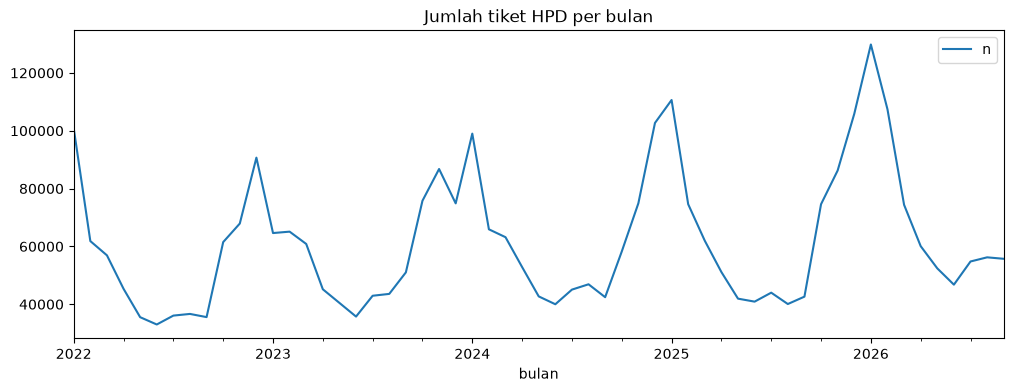

In [18]:
import matplotlib.pyplot as plt

bulanan = con.sql("""
    SELECT DATE_TRUNC('month', created_date) AS bulan, COUNT(*) AS n
    FROM raw
    GROUP BY bulan
    ORDER BY bulan
""").df()

bulanan.plot(x="bulan", y="n", figsize=(12, 4), title="Jumlah tiket HPD per bulan")
bulanan